In [17]:
# ============================================================
# SETUP
# ============================================================
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 250)

from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import log_loss, brier_score_loss, roc_auc_score
from sklearn.calibration import calibration_curve

root_dir = "/Users/albert/Library/CloudStorage/OneDrive-andrew.cmu.edu/Documents/CMU 26-27/Undergraduate Research/Victimization/Code/capstone_victimization"
dir = root_dir + "/Data and Resources"
os.chdir(dir)
data = pd.read_csv(os.path.join(dir, "final_data.csv"))

ID_COL = "respondent_id"
TREATMENT = "timely_college"
OUTCOME = "violent_victimization_18_24"

numeric_features = [
    "total_number_of_incarcerations",
    "days_r_absent_from_school",
    "r_threatened_to_be_hurt_at_school",
    "r_in_a_fight_at_school",
    "household_net_worth",
    "household_size",
    "asvab_math_verbal_score_percent",
]
categorical_features = [
    "teachers_good",
    "discipline_is_fair_agree_disagree",
    "percent_of_peers_who_smoke",
    "percent_of_peers_who_get_drunk_1_times_a_month",
    "percent_of_peers_belong_to_a_gang",
    "percent_of_peers_who_have_had_sex",
    "bullying_victim_before_age_12",
    "r_victim_of_bullying_12_18_years",
    "earliest_arrest_before_18",
    "sex",
    "r_ever_live_through_hard_times",
    "biological_father_education",   # 95 = ungraded
    "biological_mother_education",   # 95 = ungraded
    "race_ethnicity",
    "mother_serve_prison_sentence",
    "father_serve_prison_sentence",
]
model_features = numeric_features + categorical_features

In [18]:
# ============================================================
# STEP 1: LOAD, CLEAN MISSING CODES, DEFINE THE OUTCOME ANALYSIS SAMPLE
# ============================================================

print(f"loaded: {data.shape[0]:,} rows x {data.shape[1]} columns")

# NLSY97 missing codes (-1..-5) are negative -> NaN. Done for covariates, treatment and outcome.
num_cols = data.select_dtypes(include="number").columns.difference([ID_COL])
data[num_cols] = data[num_cols].mask(data[num_cols] < 0)

# Analysis sample: treatment AND outcome known. Unknown outcomes are dropped, never coded 0.
n_all = len(data)
n_trt = data[TREATMENT].notna().sum()
keep = data[TREATMENT].notna() & data[OUTCOME].notna()
print(f"treatment defined          : {n_trt:,} / {n_all:,}")
print(f"  ...of which outcome known : {keep.sum():,}  (outcome unknown -> excluded: {n_trt - keep.sum():,})")

X_a = data.loc[keep, model_features].copy()          # same covariates for every model
z_a = data.loc[keep, TREATMENT].astype(int)
y_a = data.loc[keep, OUTCOME].astype(int)
assert set(y_a.unique()) <= {0, 1} and set(z_a.unique()) <= {0, 1}, "treatment/outcome must be 0/1"
XZ = X_a.assign(**{TREATMENT: z_a})                   # outcome-model design: covariates + treatment
n = len(y_a)

print(f"\nanalysis sample n = {n:,}")
print(pd.DataFrame({
    "n": [int((z_a == 1).sum()), int((z_a == 0).sum())],
    "n_victimized": [int(y_a[z_a == 1].sum()), int(y_a[z_a == 0].sum())],
    "raw_rate_%": [100 * y_a[z_a == 1].mean(), 100 * y_a[z_a == 0].mean()],
}, index=["Z=1 timely", "Z=0 not timely"]).round(2).to_string())

dropped = data.loc[data[TREATMENT].notna() & ~keep]
print(f"\nrespondents dropped for unknown outcome, by arm: "
      f"Z=1: {(dropped[TREATMENT] == 1).sum():,}, Z=0: {(dropped[TREATMENT] == 0).sum():,}")
miss = X_a.isna().mean().mul(100).round(1)
print("\ncovariate missingness (imputed inside each CV fold):")
print(miss[miss > 0].sort_values(ascending=False).to_string() or "  none")

loaded: 8,984 rows x 26 columns
treatment defined          : 8,846 / 8,984
  ...of which outcome known : 8,467  (outcome unknown -> excluded: 379)

analysis sample n = 8,467
                   n  n_victimized  raw_rate_%
Z=1 timely      3987           233        5.84
Z=0 not timely  4480           287        6.41

respondents dropped for unknown outcome, by arm: Z=1: 171, Z=0: 208

covariate missingness (imputed inside each CV fold):
percent_of_peers_who_have_had_sex                 56.3
household_net_worth                               30.7
father_serve_prison_sentence                      23.8
biological_father_education                       20.7
asvab_math_verbal_score_percent                   20.2
r_victim_of_bullying_12_18_years                  18.8
mother_serve_prison_sentence                      17.2
r_ever_live_through_hard_times                    12.0
biological_mother_education                        7.7
days_r_absent_from_school                          3.3
percent_of_p

In [19]:
# ============================================================
# MODEL DEFINITIONS
# ============================================================
def make_preprocessor(include_treatment, scale_numeric=False):
    # median-impute numeric, most-frequent-impute categorical, one-hot categorical.
    # Lives inside each Pipeline, so imputation is re-fit on each training fold only.
    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        num_steps.append(("scaler", StandardScaler()))
    parts = [
        ("num", Pipeline(num_steps), numeric_features),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), categorical_features),
    ]
    if include_treatment:
        parts.append(("trt", "passthrough", [TREATMENT]))     # 0/1, left unscaled
    return ColumnTransformer(parts)


# Tuning knobs. Regularized logistic; shallow / regularized trees.
OUTCOME_PARAMS = {
    "logit": dict(C=0.5, max_iter=2000),
    # max_features is high on purpose so the treatment column is available at most splits
    "rf":    dict(n_estimators=500, max_depth=5, min_samples_leaf=30, max_features=0.5),
    "xgb":   dict(n_estimators=200, max_depth=3, learning_rate=0.05, subsample=0.8,
                  colsample_bytree=0.8, min_child_weight=5, reg_lambda=5.0),
}
# Propensity procedure used by AIPW - prespecify it once, identical for every outcome model.
PS_MODEL = "logit"
PS_PARAMS = {
    "logit": dict(C=1.0, max_iter=2000),
    "rf":    dict(n_estimators=500, max_depth=5, min_samples_leaf=30, max_features="sqrt"),
    "xgb":   dict(n_estimators=200, max_depth=3, learning_rate=0.05, subsample=0.8,
                  colsample_bytree=0.8, min_child_weight=5, reg_lambda=5.0),
}


def build_classifier(kind, params, seed):
    if kind == "logit":
        return LogisticRegression(**params)
    if kind == "rf":
        return RandomForestClassifier(**params, n_jobs=-1, random_state=seed)
    if kind == "xgb":
        return XGBClassifier(**params, eval_metric="logloss", n_jobs=-1, random_state=seed)
    raise ValueError(kind)


def make_outcome_model(kind, seed):
    return Pipeline([("prep", make_preprocessor(True, scale_numeric=(kind == "logit"))),
                     ("clf", build_classifier(kind, OUTCOME_PARAMS[kind], seed))])


def make_ps_model(kind, seed):
    return Pipeline([("prep", make_preprocessor(False, scale_numeric=(kind == "logit"))),
                     ("clf", build_classifier(kind, PS_PARAMS[kind], seed))])

In [20]:
# ============================================================
# STEP 2: CROSS-FIT THE THREE OUTCOME MODELS (+ the propensity model for AIPW)
# ============================================================
MODELS = ["logit", "rf", "xgb"]
SEEDS = [0, 1, 2]
N_SPLITS = 5

# One fold assignment per seed, SHARED by all three outcome models and the propensity model.
# Stratified on treatment x outcome so every fold has all four cells.
strat = (z_a * 2 + y_a).values
folds = {s: list(StratifiedKFold(N_SPLITS, shuffle=True, random_state=s).split(XZ, strat)) for s in SEEDS}


def crossfit_outcome(kind, seed):
    # Out-of-fold predictions of P(Y=1 | X, Z=1) and P(Y=1 | X, Z=0) for every respondent,
    # from a model that never saw that respondent.
    mu1, mu0 = np.zeros(n), np.zeros(n)
    for tr, te in folds[seed]:
        m = make_outcome_model(kind, seed).fit(XZ.iloc[tr], y_a.iloc[tr])
        Xte = XZ.iloc[te]
        mu1[te] = m.predict_proba(Xte.assign(**{TREATMENT: 1}))[:, 1]
        mu0[te] = m.predict_proba(Xte.assign(**{TREATMENT: 0}))[:, 1]
    return mu1, mu0


def crossfit_ps(kind, seed):
    e = np.zeros(n)
    for tr, te in folds[seed]:
        m = make_ps_model(kind, seed).fit(X_a.iloc[tr], z_a.iloc[tr])
        e[te] = m.predict_proba(X_a.iloc[te])[:, 1]
    return e


oof = {s: {} for s in SEEDS}      # oof[seed][model] = (mu1, mu0)
ps_oof = {}                       # ps_oof[seed] = out-of-fold propensity scores
for s in SEEDS:
    t0 = time.time()
    ps_oof[s] = crossfit_ps(PS_MODEL, s)
    for m in MODELS:
        oof[s][m] = crossfit_outcome(m, s)
    print(f"seed {s}: done in {time.time() - t0:.1f}s")

seed 0: done in 6.4s
seed 1: done in 5.6s
seed 2: done in 6.0s


Out-of-fold performance (mean over seeds; lower log_loss/brier better, higher auc better):
                         log_loss   brier     auc  mean_pred_%  observed_%  log_loss_sd_across_seeds  brier_sd_across_seeds  auc_sd_across_seeds
arm     model                                                                                                                                   
all     logit              0.2315  0.0579  0.5754       6.1624      6.1415                    0.0002                 0.0001               0.0024
        prevalence only    0.2308  0.0576  0.5000          NaN         NaN                       NaN                    NaN                  NaN
        rf                 0.2264  0.0571  0.6108       6.1527      6.1415                    0.0004                 0.0001               0.0025
        xgb                0.2300  0.0577  0.5853       6.1286      6.1415                    0.0006                 0.0001               0.0053
control logit              0.2396  0.06

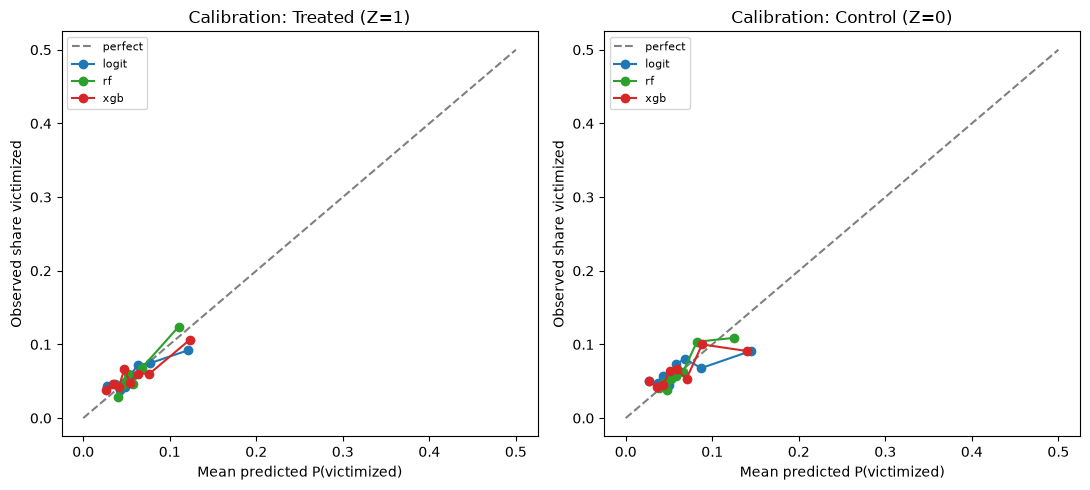

In [21]:
# ============================================================
# STEP 3: OUTCOME-MODEL PERFORMANCE (diagnostics, NOT the selection criterion on their own)
# ============================================================
# Evaluated on the FACTUAL outcome: for each respondent, the prediction under the treatment
# they actually received.
EPSP = 1e-6
N_CAL_BINS = 8


def factual_pred(mu1, mu0):
    return np.where(z_a.values == 1, mu1, mu0)


def metrics(y, p):
    p = np.clip(p, EPSP, 1 - EPSP)
    return {"log_loss": log_loss(y, p), "brier": brier_score_loss(y, p),
            "auc": roc_auc_score(y, p), "mean_pred_%": 100 * p.mean(), "observed_%": 100 * np.mean(y)}


arms = {"all": np.ones(n, bool), "treated": z_a.values == 1, "control": z_a.values == 0}
rows = []
for s in SEEDS:
    for m in MODELS:
        p = factual_pred(*oof[s][m])
        for arm, mask_arm in arms.items():
            rows.append({"seed": s, "model": m, "arm": arm, **metrics(y_a.values[mask_arm], p[mask_arm])})
perf = pd.DataFrame(rows)

# Reference: a model that only predicts the overall prevalence in that group
base = []
for arm, mask_arm in arms.items():
    yy = y_a.values[mask_arm]
    base.append({"model": "prevalence only", "arm": arm,
                 "log_loss": log_loss(yy, np.full(len(yy), yy.mean())),
                 "brier": brier_score_loss(yy, np.full(len(yy), yy.mean())), "auc": 0.5})

mean_tbl = perf.groupby(["arm", "model"])[["log_loss", "brier", "auc", "mean_pred_%", "observed_%"]].mean()
sd_tbl = perf.groupby(["arm", "model"])[["log_loss", "brier", "auc"]].std().add_suffix("_sd_across_seeds")
tbl = mean_tbl.join(sd_tbl)
tbl = pd.concat([tbl, pd.DataFrame(base).set_index(["arm", "model"])]).sort_index()
print("Out-of-fold performance (mean over seeds; lower log_loss/brier better, higher auc better):")
print(tbl.round(4).to_string())

# Calibration, separately for treated and control (first seed's out-of-fold predictions)
styles = {"logit": "tab:blue", "rf": "tab:green", "xgb": "tab:red"}
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, (arm, title) in zip(axes, [("treated", "Treated (Z=1)"), ("control", "Control (Z=0)")]):
    ax.plot([0, 0.5], [0, 0.5], color="gray", linestyle="--", label="perfect")
    for m in MODELS:
        p = factual_pred(*oof[SEEDS[0]][m])[arms[arm]]
        frac, mean_p = calibration_curve(y_a.values[arms[arm]], p, n_bins=N_CAL_BINS, strategy="quantile")
        ax.plot(mean_p, frac, marker="o", color=styles[m], label=m)
    ax.set_title(f"Calibration: {title}")
    ax.set_xlabel("Mean predicted P(victimized)")
    ax.set_ylabel("Observed share victimized")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [22]:
# ============================================================
# STEP 5: LOCK THE SPECIFICATION - run this BEFORE looking at any effect estimate
# ============================================================
# Decide from the Step 3 diagnostics ONLY (log loss, Brier, calibration, seed stability),
# not from which model gives a preferred ATE.
PRIMARY_MODEL = "logit"        # "logit" | "rf" | "xgb"
PS_CLIP = None                 # None = no truncation (EPS guard only). e.g. 0.01 for a sensitivity run
EPS = 1e-6

SPEC = {
    "analysis_sample": f"treatment and outcome both known, n={n:,}; unknown outcomes excluded, not coded 0",
    "covariates": model_features,
    "missing_covariates": "median / most-frequent imputation, fit within each training fold",
    "outcome_model_primary": PRIMARY_MODEL,
    "outcome_params": OUTCOME_PARAMS[PRIMARY_MODEL],
    "propensity_model": f"{PS_MODEL} {PS_PARAMS[PS_MODEL]} (cross-fitted, same folds)",
    "cross_fitting": f"{N_SPLITS}-fold, folds shared across all models, seeds {SEEDS}",
    "seed_handling": "estimate computed separately per seed; reported = median across seeds, "
                     "SE includes between-seed variability; predictions NOT averaged across seeds",
    "estimators": "g-computation (outcome-model-only) and AIPW (doubly robust), both ATE (risk difference)",
    "score_truncation": "none" if PS_CLIP is None else f"scores clipped to [{PS_CLIP}, {1 - PS_CLIP}]",
}
print("LOCKED SPECIFICATION (record before interpreting any estimate):")
for k, v in SPEC.items():
    print(f"  {k}: {v}")

LOCKED SPECIFICATION (record before interpreting any estimate):
  analysis_sample: treatment and outcome both known, n=8,467; unknown outcomes excluded, not coded 0
  covariates: ['total_number_of_incarcerations', 'days_r_absent_from_school', 'r_threatened_to_be_hurt_at_school', 'r_in_a_fight_at_school', 'household_net_worth', 'household_size', 'asvab_math_verbal_score_percent', 'teachers_good', 'discipline_is_fair_agree_disagree', 'percent_of_peers_who_smoke', 'percent_of_peers_who_get_drunk_1_times_a_month', 'percent_of_peers_belong_to_a_gang', 'percent_of_peers_who_have_had_sex', 'bullying_victim_before_age_12', 'r_victim_of_bullying_12_18_years', 'earliest_arrest_before_18', 'sex', 'r_ever_live_through_hard_times', 'biological_father_education', 'biological_mother_education', 'race_ethnicity', 'mother_serve_prison_sentence', 'father_serve_prison_sentence']
  missing_covariates: median / most-frequent imputation, fit within each training fold
  outcome_model_primary: logit
  outcome

# Grouped Permuation Importance
How much predictive performance worsens when each original covariate is shuffled.

Note: categorical variables permuted as whole, rather than their one-hot encoded.

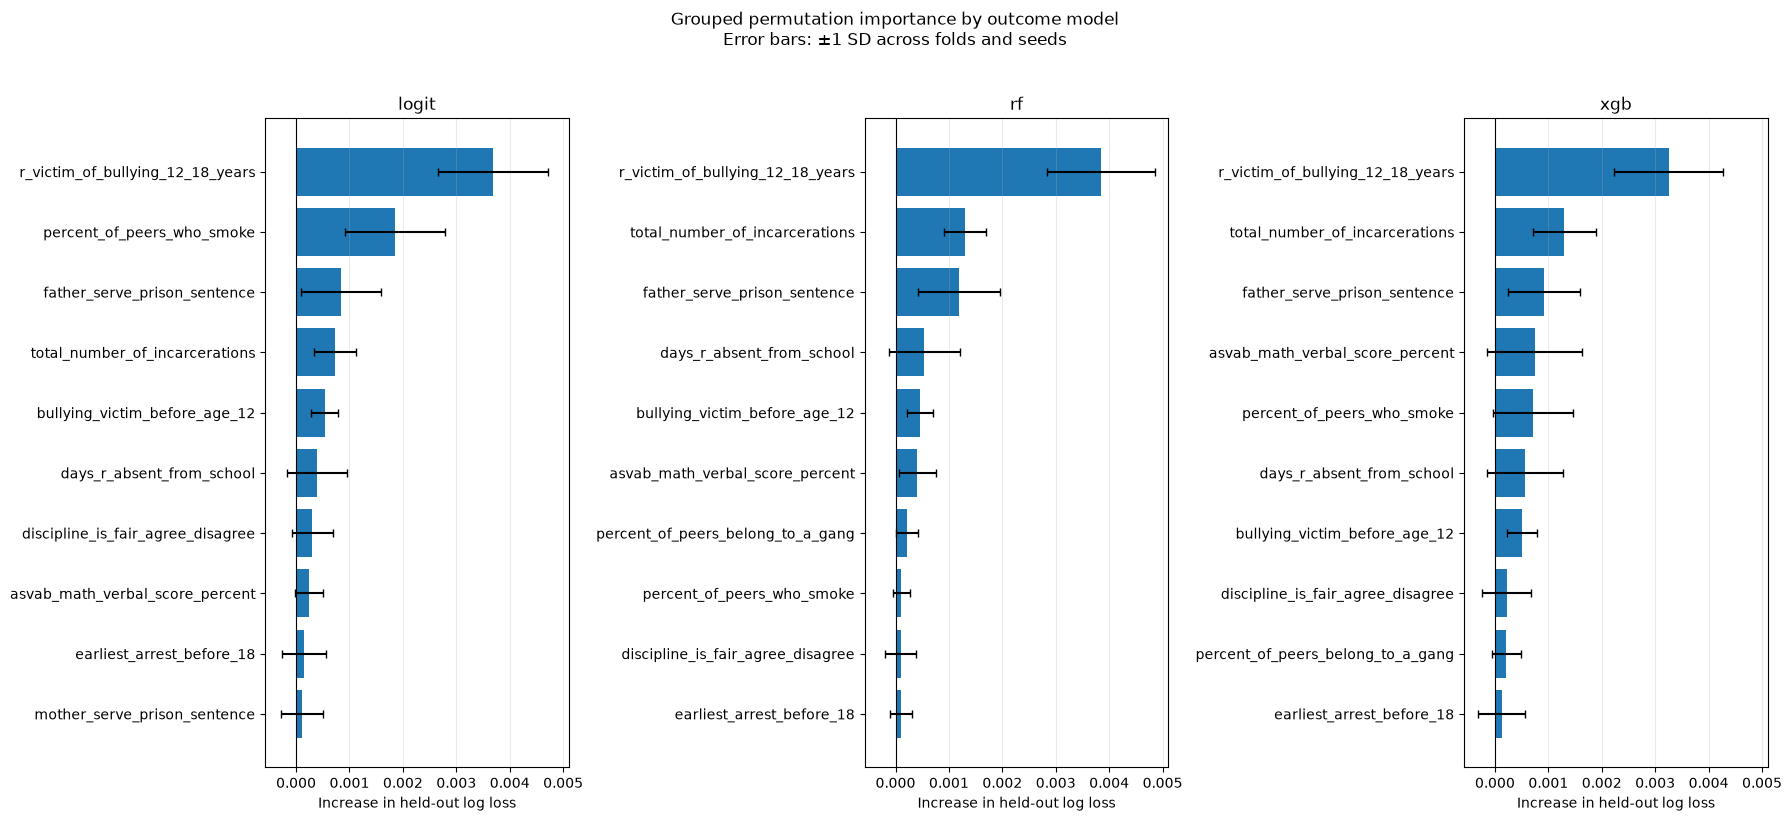

,model,feature,mean_importance,sd_across_folds_seeds
18,logit,r_victim_of_bullying_12_18_years,0.0037,0.0010
14,logit,percent_of_peers_who_smoke,0.0019,0.0009
7,logit,father_serve_prison_sentence,0.0008,0.0007
22,logit,total_number_of_incarcerations,0.0007,0.0004
3,logit,bullying_victim_before_age_12,0.0005,0.0002
4,logit,days_r_absent_from_school,0.0004,0.0006
5,logit,discipline_is_fair_agree_disagree,0.0003,0.0004
0,logit,asvab_math_verbal_score_percent,0.0002,0.0003
6,logit,earliest_arrest_before_18,0.0002,0.0004
10,logit,mother_serve_prison_sentence,0.0001,0.0004


In [23]:
from sklearn.metrics import log_loss
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

N_PERMUTATIONS = 10
EPSP = 1e-6

importance_rows = []

for seed in SEEDS:
    for fold_idx, (tr, te) in enumerate(folds[seed]):
        X_train = XZ.iloc[tr]
        X_test = XZ.iloc[te]
        y_train = y_a.iloc[tr].to_numpy()
        y_test = y_a.iloc[te].to_numpy()

        for kind in MODELS:
            model = make_outcome_model(kind, seed)
            model.fit(X_train, y_train)

            baseline_pred = np.clip(
                model.predict_proba(X_test)[:, 1],
                EPSP, 1 - EPSP
            )
            baseline_loss = log_loss(y_test, baseline_pred, labels=[0, 1])

            for feature_idx, feature in enumerate(model_features):
                increases = []

                for rep in range(N_PERMUTATIONS):
                    X_perm = X_test.copy()

                    rng = np.random.default_rng(
                        seed * 100000
                        + fold_idx * 10000
                        + feature_idx * 100
                        + rep
                    )

                    # Shuffle the original covariate as a group,
                    # before the pipeline's imputation and one-hot encoding.
                    X_perm[feature] = rng.permutation(
                        X_perm[feature].to_numpy()
                    )

                    perm_pred = np.clip(
                        model.predict_proba(X_perm)[:, 1],
                        EPSP, 1 - EPSP
                    )
                    perm_loss = log_loss(
                        y_test, perm_pred, labels=[0, 1]
                    )
                    increases.append(perm_loss - baseline_loss)

                importance_rows.append({
                    "seed": seed,
                    "fold": fold_idx + 1,
                    "model": kind,
                    "feature": feature,
                    "importance": np.mean(increases),
                })

importance_detail = pd.DataFrame(importance_rows)

# First average over permutations (already done), then summarize across folds/seeds.
importance_summary = (
    importance_detail
    .groupby(["model", "feature"])["importance"]
    .agg(["mean", "std"])
    .reset_index()
    .rename(columns={
        "mean": "mean_importance",
        "std": "sd_across_folds_seeds",
    })
)

importance_summary["sd_across_folds_seeds"] = (
    importance_summary["sd_across_folds_seeds"].fillna(0)
)

# Plot the top 10 features separately for each model.
fig, axes = plt.subplots(1, len(MODELS), figsize=(18, 8), sharex=True)

for ax, kind in zip(axes, MODELS):
    plot_df = (
        importance_summary[importance_summary["model"] == kind]
        .nlargest(10, "mean_importance")
        .sort_values("mean_importance")
    )

    ax.barh(
        plot_df["feature"],
        plot_df["mean_importance"],
        xerr=plot_df["sd_across_folds_seeds"],
        capsize=3,
    )
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(kind)
    ax.set_xlabel("Increase in held-out log loss")
    ax.grid(axis="x", alpha=0.25)

fig.suptitle(
    "Grouped permutation importance by outcome model\n"
    "Error bars: ±1 SD across folds and seeds",
    y=1.02,
)
plt.tight_layout()
plt.show()

display(
    importance_summary.sort_values(
        ["model", "mean_importance"],
        ascending=[True, False],
    ).round(4)
)

# Direction and Model Agreement
Continuous: compares 25th and 75th percentiles
Categorical: compares "sufficiently common" with most common

In [24]:
# ============================================================
# DIRECTION AND MODEL AGREEMENT
# ============================================================

DIRECTION_THRESHOLD_PP = 0.1
MIN_CATEGORY_N = max(20, int(np.ceil(0.01 * len(X_a))))

direction_rows = []

# Define contrasts from the analysis sample.
numeric_contrasts = {}
for feature in numeric_features:
    values = X_a[feature].dropna()
    numeric_contrasts[feature] = (
        values.quantile(0.25),
        values.quantile(0.75),
    )

categorical_contrasts = {}
for feature in categorical_features:
    counts = X_a[feature].dropna().value_counts()

    if counts.empty:
        continue

    reference = counts.index[0]
    levels = counts[counts >= MIN_CATEGORY_N].index.tolist()

    categorical_contrasts[feature] = {
        "reference": reference,
        "levels": [level for level in levels if level != reference],
    }


def average_predicted_risk(model, X_test, feature, value):
    """Change one original feature, keep treatment and other covariates fixed."""
    X_changed = X_test.copy()
    X_changed[feature] = value
    return model.predict_proba(X_changed)[:, 1].mean()


for seed in SEEDS:
    for fold_idx, (tr, te) in enumerate(folds[seed]):
        X_train = XZ.iloc[tr]
        X_test = XZ.iloc[te]
        y_train = y_a.iloc[tr].to_numpy()

        for kind in MODELS:
            model = make_outcome_model(kind, seed)
            model.fit(X_train, y_train)

            # Continuous features: Q75 versus Q25
            for feature, (q25, q75) in numeric_contrasts.items():
                risk_low = average_predicted_risk(
                    model, X_test, feature, q25
                )
                risk_high = average_predicted_risk(
                    model, X_test, feature, q75
                )

                direction_rows.append({
                    "seed": seed,
                    "fold": fold_idx + 1,
                    "model": kind,
                    "feature": feature,
                    "contrast": f"Q75 ({q75:.3g}) vs Q25 ({q25:.3g})",
                    "risk_difference_pp": 100 * (risk_high - risk_low),
                })

            # Categorical features: category versus most common category
            for feature, info in categorical_contrasts.items():
                reference = info["reference"]
                risk_reference = average_predicted_risk(
                    model, X_test, feature, reference
                )

                for level in info["levels"]:
                    risk_level = average_predicted_risk(
                        model, X_test, feature, level
                    )

                    direction_rows.append({
                        "seed": seed,
                        "fold": fold_idx + 1,
                        "model": kind,
                        "feature": feature,
                        "contrast": f"{level} vs {reference}",
                        "risk_difference_pp": (
                            100 * (risk_level - risk_reference)
                        ),
                    })

direction_detail = pd.DataFrame(direction_rows)

# Summarize estimates across folds and seeds.
direction_summary = (
    direction_detail
    .groupby(["feature", "contrast", "model"])["risk_difference_pp"]
    .agg(["mean", "std"])
    .reset_index()
    .rename(columns={
        "mean": "risk_difference_pp",
        "std": "sd_across_folds_seeds_pp",
    })
)


def direction_arrow(value):
    if value > DIRECTION_THRESHOLD_PP:
        return "↑ Higher"
    if value < -DIRECTION_THRESHOLD_PP:
        return "↓ Lower"
    return "↔ Little change"


# One row per feature contrast, with a column for each model.
direction_table = direction_summary.pivot(
    index=["feature", "contrast"],
    columns="model",
    values="risk_difference_pp",
).reset_index()

for kind in MODELS:
    direction_table[f"{kind}_direction"] = (
        direction_table[kind].apply(direction_arrow)
    )

def model_agreement(row):
    directions = [direction_arrow(row[kind]) for kind in MODELS]
    clear_directions = [d for d in directions if d != "↔ Little change"]

    if len(clear_directions) == 3 and len(set(clear_directions)) == 1:
        return "3/3 agree"
    if len(clear_directions) == 2 and len(set(clear_directions)) == 1:
        return "2 agree; 1 little change"
    if len(clear_directions) == 0:
        return "All little change"
    return "Mixed"

direction_table["agreement"] = direction_table.apply(
    model_agreement, axis=1
)

display_cols = [
    "feature", "contrast",
    "logit_direction", "rf_direction", "xgb_direction",
    "logit", "rf", "xgb",
    "agreement",
]

direction_table = direction_table[display_cols].rename(columns={
    "logit": "logit_risk_difference_pp",
    "rf": "rf_risk_difference_pp",
    "xgb": "xgb_risk_difference_pp",
})

display(direction_table.round(2))

model,feature,contrast,logit_direction,rf_direction,xgb_direction,logit_risk_difference_pp,rf_risk_difference_pp,xgb_risk_difference_pp,agreement
0,asvab_math_verbal_score_percent,Q75 (70.1) vs Q25 (19.2),↑ Higher,↑ Higher,↑ Higher,0.78,0.84,2.89,3/3 agree
1,biological_father_education,10.0 vs 12.0,↓ Lower,↔ Little change,↓ Lower,-1.34,-0.02,-0.68,2 agree; 1 little change
2,biological_father_education,11.0 vs 12.0,↔ Little change,↔ Little change,↔ Little change,-0.03,0.03,0.08,All little change
3,biological_father_education,13.0 vs 12.0,↑ Higher,↑ Higher,↑ Higher,1.04,0.19,0.53,3/3 agree
4,biological_father_education,14.0 vs 12.0,↑ Higher,↑ Higher,↑ Higher,1.42,0.29,0.87,3/3 agree
5,biological_father_education,15.0 vs 12.0,↑ Higher,↑ Higher,↑ Higher,1.77,0.49,0.65,3/3 agree
6,biological_father_education,16.0 vs 12.0,↔ Little change,↔ Little change,↔ Little change,-0.02,-0.02,-0.07,All little change
7,biological_father_education,17.0 vs 12.0,↔ Little change,↔ Little change,↑ Higher,0.07,0.08,0.10,Mixed
8,biological_father_education,18.0 vs 12.0,↓ Lower,↔ Little change,↔ Little change,-0.35,-0.02,0.00,Mixed
9,biological_father_education,20.0 vs 12.0,↑ Higher,↑ Higher,↑ Higher,1.79,0.25,0.36,3/3 agree
